In [1]:
import os
import re
import sys
sys.path.append('..')
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from cmap import Colormap

mpl.rcParams['font.family'] = 'arial'
mpl.rcParams['font.size'] = 10

sensor_colors = [
    '#8686D2',
    '#7BAED3',
    '#9CCBA0',
    '#E6DC84',
    '#D47291',
    '#868686',
]

# Alcohol

In [2]:
alcohol_data_dir = '../data/blood_alcohol_spectra/'
files = os.listdir(alcohol_data_dir)

# Filter for files matching the pattern 0_xx_alc_slide.csv (with the '1' suffix)
pattern = r'^0_(\d{2})_alc_slide1\.csv$'
filtered_files = []
alcohol_concentrations = []

for file in files:
    match = re.match(pattern, file)
    if match:
        filtered_files.append(file)
        # Extract the two digits and convert to decimal
        digits = match.group(1)
        concentration = float(f"0.{digits}")
        alcohol_concentrations.append(concentration)

# Sort both lists by concentration
sorted_pairs = sorted(zip(alcohol_concentrations, filtered_files))
alcohol_concentrations = [pair[0] for pair in sorted_pairs]
filtered_files = [pair[1] for pair in sorted_pairs]

print("Filtered filenames:")
for file in filtered_files:
    print(f"  {file}")

print(f"\nCorresponding alcohol concentrations:")
for conc in alcohol_concentrations:
    print(f"  {conc}")

print(f"\nTotal files found: {len(filtered_files)}")

Filtered filenames:
  0_00_alc_slide1.csv
  0_02_alc_slide1.csv
  0_05_alc_slide1.csv
  0_08_alc_slide1.csv
  0_10_alc_slide1.csv
  0_15_alc_slide1.csv
  0_20_alc_slide1.csv
  0_30_alc_slide1.csv
  0_40_alc_slide1.csv

Corresponding alcohol concentrations:
  0.0
  0.02
  0.05
  0.08
  0.1
  0.15
  0.2
  0.3
  0.4

Total files found: 9


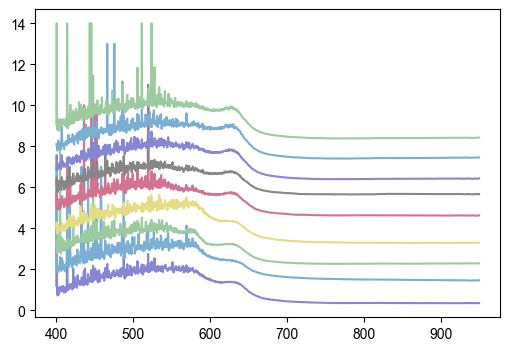

In [3]:
# plot raw data
plt.figure(figsize=(6, 4))
for i, file in enumerate(filtered_files):
    data = pd.read_csv(os.path.join(alcohol_data_dir, file), skiprows=9, header=None)
    wavelength = data.iloc[:, 0].values
    intensity = data.iloc[:, 1].values

    plt.plot(wavelength, intensity + i * 1, color=sensor_colors[i % len(sensor_colors)], label=f'{alcohol_concentrations[i]:.2f} BAC')

# Acetaldehyde

In [4]:
acetaldehyde_data_dir = '../data/blood_acetaldehyde_spectra/'
files = os.listdir(acetaldehyde_data_dir)

# Group acetaldehyde files by concentration
aceta_0_02_files = [f for f in files if f.startswith('aceta_0_02_window_size1_')]
aceta_0_40_files = [f for f in files if f.startswith('aceta_0_40_window_size1_')]

# Function to calculate average spectrum for a group of files
def calculate_average_spectrum(file_list, data_dir):
    all_spectra = []
    wavelength = None
    
    for file in file_list:
        file_path = os.path.join(data_dir, file)
        data = pd.read_csv(file_path, skiprows=9, header=None, names=['wavelength', 'absorbance'])
        if wavelength is None:
            wavelength = data['wavelength'].values
        all_spectra.append(data['absorbance'].values)
    
    avg_spectrum = np.mean(all_spectra, axis=0)
    return pd.DataFrame({'wavelength': wavelength, 'absorbance': avg_spectrum})

# Calculate averages for each concentration group
acetaldehyde_avg_data = {
    0.02: calculate_average_spectrum(aceta_0_02_files, acetaldehyde_data_dir),
    0.40: calculate_average_spectrum(aceta_0_40_files, acetaldehyde_data_dir)
}

# Combine alcohol and acetaldehyde data
all_concentrations = alcohol_concentrations + [0.02, 0.40]
all_files = filtered_files + ['acetaldehyde_0_02_avg', 'acetaldehyde_0_40_avg']

# Sort by concentration
sorted_pairs = sorted(zip(all_concentrations, all_files))
all_concentrations = [pair[0] for pair in sorted_pairs]
all_files = [pair[1] for pair in sorted_pairs]

In [5]:
# Load and preprocess all data before plotting
processed_data = []
for i, file in enumerate(all_files):
    if file.startswith('acetaldehyde_'):
        # Handle averaged acetaldehyde data
        concentration = all_concentrations[i]
        data = acetaldehyde_avg_data[concentration]
    else:
        # Handle alcohol files
        file_path = os.path.join(alcohol_data_dir, file)
        data = pd.read_csv(file_path, skiprows=9, header=None, names=['wavelength', 'absorbance'])
    
    log_absorbance = np.log(data['absorbance'] + 1e-6)  # Avoid log(0)
    log_absorbance = savgol_filter(log_absorbance, window_length=121, polyorder=2)
    processed_data.append({'wavelength': data['wavelength'], 'log_absorbance': log_absorbance})

# find the wavelength array and the absorbance array of the median spectrum
S = np.vstack([d['log_absorbance'] for d in processed_data])                    # [N, L]
w = np.median(np.vstack([d['wavelength'] for d in processed_data]), axis=0)     # [L]

keep = (w >= 410) & (w <= 950)
w = w[keep]
S = S[:, keep]
r = np.median(S, axis=0)

X = np.vstack([np.ones_like(w), w, w**2, r]).T      # [L, 4]
XtX_inv = np.linalg.pinv(X.T @ X)                   # precompute for efficiency
Xt = X.T

S_emsc = np.empty_like(S)
for i, s in enumerate(S):
    a = XtX_inv @ Xt @ s
    S_emsc[i] = (s - (a[0] + a[1]*w + a[2]*w**2)) / (a[3] if a[3]!=0 else 1.0)

# For Fig2

## processed spectra

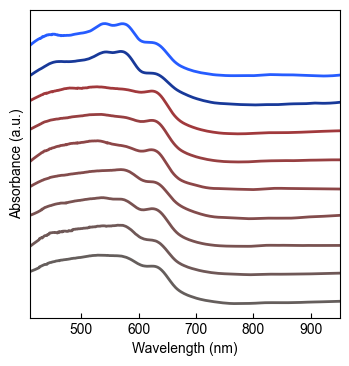

In [6]:
cm = Colormap(['#655e5c', '#c92127'])
colors = cm(np.linspace(0, 1, len(all_files)))

# Define unique colors for acetaldehyde data
acetaldehyde_colors = ['#183999', '#265cff']

exclude_indices = [5, 9]  # e.g., [0, 3, 5] to exclude specific positions

# Apply exclusions
included_indices = []
for i in range(len(all_files)):
    if (i not in exclude_indices):
        included_indices.append(i)

y_offset = 1.0

plt.figure(figsize=(4, 4))

# Separate and sort alcohol and acetaldehyde indices from included data
alcohol_indices = [i for i in included_indices if not all_files[i].startswith('acetaldehyde_')]
acetaldehyde_indices = [i for i in included_indices if all_files[i].startswith('acetaldehyde_')]

# Sort alcohol indices by concentration (ascending)
alcohol_indices.sort(key=lambda x: all_concentrations[x])
# Sort acetaldehyde indices by concentration (ascending)
acetaldehyde_indices.sort(key=lambda x: all_concentrations[x])

# Plot alcohol data first (bottom to top: 0.00, 0.02, 0.05, ..., 0.40)
for plot_idx, i in enumerate(alcohol_indices):
    s = S_emsc[i]
    concentration = all_concentrations[i]
    color = colors[plot_idx % len(colors)]
    label = f'{concentration:.2f}% alcohol'
    
    plt.plot(w, s + plot_idx * y_offset, 
             color=color, linewidth=2, 
             label=label)

# Plot acetaldehyde data on top (0.02 acetaldehyde, 0.40 acetaldehyde)
for plot_idx, i in enumerate(acetaldehyde_indices):
    s = S_emsc[i]
    concentration = all_concentrations[i]
    color = acetaldehyde_colors[plot_idx % len(acetaldehyde_colors)]
    label = f'{concentration:.2f}% acetaldehyde (avg)'
    
    # Place acetaldehyde above all alcohol data
    plt.plot(w, s + (len(alcohol_indices) + plot_idx) * y_offset, 
             color=color, linewidth=2, 
             label=label)

plt.xlabel('Wavelength (nm)')
plt.ylabel('Absorbance (a.u.)')
plt.yticks([])

plt.xlim(410, 950)
# plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tick_params(direction='in')

# save the current axis position for reproducing later
pos_ax = plt.gca().get_position()

# plt.savefig('../figures/fig2/blood_alcohol_acetaldehyde_spectra.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

## save processed spectra

In [7]:
# Save the displayed data to CSV file
output_data = []

# Add alcohol data
for plot_idx, i in enumerate(alcohol_indices):
    concentration = all_concentrations[i]
    spectrum_data = S_emsc[i]
    
    # Create column for this spectrum
    column_name = f'{concentration:.2f}%_alcohol'
    if len(output_data) == 0:
        # Initialize with wavelength column
        output_data = [{'wavelength': w[j], column_name: spectrum_data[j]} for j in range(len(w))]
    else:
        # Add this spectrum to existing data
        for j in range(len(w)):
            output_data[j][column_name] = spectrum_data[j]

# Add acetaldehyde data
for plot_idx, i in enumerate(acetaldehyde_indices):
    concentration = all_concentrations[i]
    spectrum_data = S_emsc[i]
    
    column_name = f'{concentration:.2f}%_acetaldehyde_avg'
    for j in range(len(w)):
        output_data[j][column_name] = spectrum_data[j]

# Convert to DataFrame and save
df_output = pd.DataFrame(output_data)
output_filename = '../data/displayed_spectra_data.csv'
# df_output.to_csv(output_filename, index=False)

# print(f"Data saved to: {output_filename}")
# print(f"Shape: {df_output.shape}")
# print(f"Columns: {list(df_output.columns)}")

## peak analysis

In [8]:
peak_analysis_data_path = '../figures/fig2/unified_reference_trends.csv'
peak_analysis_df = pd.read_csv(peak_analysis_data_path)
print("\nPeak analysis data:")
print(peak_analysis_df.head())


Peak analysis data:
    series  concentration_%  alpha_peak_abs  beta_peak_abs  A630_abs  \
0  alcohol             0.00        1.661518       1.683595  1.279796   
1  alcohol             0.05        1.730080       1.711569  1.172177   
2  alcohol             0.08        1.642580       1.694273  1.282706   
3  alcohol             0.10        1.709679       1.688734  1.252297   
4  alcohol             0.20        1.548719       1.695908  1.340711   

   alpha_rel_to_0.00BAC  beta_rel_to_0.00BAC  A630_rel_to_0.00BAC  
0              1.000000             1.000000             1.000000  
1              1.041265             1.016615             0.915909  
2              0.988602             1.006342             1.002273  
3              1.028986             1.003053             0.978513  
4              0.932111             1.007313             1.047597  


In [9]:
# Examine the complete dataset and calculate trend lines
print("Complete peak analysis data:")
print(peak_analysis_df)
print(f"\nDataset shape: {peak_analysis_df.shape}")
print(f"Columns: {list(peak_analysis_df.columns)}")
print(f"\nUnique series: {peak_analysis_df['series'].unique()}")

# Separate alcohol and acetaldehyde data
alcohol_data = peak_analysis_df[peak_analysis_df['series'] == 'alcohol'].copy()
acetaldehyde_data = peak_analysis_df[peak_analysis_df['series'] == 'acetaldehyde'].copy()

print(f"\nAlcohol data points: {len(alcohol_data)}")
print(f"Acetaldehyde data points: {len(acetaldehyde_data)}")

# Get the last three columns for trend analysis
relative_cols = peak_analysis_df.columns[-3:].tolist()
print(f"\nColumns for trend analysis: {relative_cols}")

# Calculate linear trend lines for each column
from scipy import stats
import numpy as np

trend_data = {}

# For alcohol data
for col in relative_cols:
    if len(alcohol_data) > 1:
        x = alcohol_data['concentration_%'].values
        y = alcohol_data[col].values
        slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)
        trend_data[f'alcohol_{col}'] = {
            'slope': slope,
            'intercept': intercept,
            'r_squared': r_value**2,
            'x_data': x,
            'y_data': y
        }
        print(f"\nAlcohol {col}:")
        print(f"  Slope: {slope:.6f}")
        print(f"  Intercept: {intercept:.6f}")
        print(f"  R²: {r_value**2:.6f}")

# For acetaldehyde data
for col in relative_cols:
    if len(acetaldehyde_data) > 1:
        x = acetaldehyde_data['concentration_%'].values
        y = acetaldehyde_data[col].values
        slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)
        trend_data[f'acetaldehyde_{col}'] = {
            'slope': slope,
            'intercept': intercept,
            'r_squared': r_value**2,
            'x_data': x,
            'y_data': y
        }
        print(f"\nAcetaldehyde {col}:")
        print(f"  Slope: {slope:.6f}")
        print(f"  Intercept: {intercept:.6f}")
        print(f"  R²: {r_value**2:.6f}")

Complete peak analysis data:
         series  concentration_%  alpha_peak_abs  beta_peak_abs  A630_abs  \
0       alcohol             0.00        1.661518       1.683595  1.279796   
1       alcohol             0.05        1.730080       1.711569  1.172177   
2       alcohol             0.08        1.642580       1.694273  1.282706   
3       alcohol             0.10        1.709679       1.688734  1.252297   
4       alcohol             0.20        1.548719       1.695908  1.340711   
5       alcohol             0.30        1.571358       1.646242  1.404640   
6       alcohol             0.40        1.563353       1.626511  1.445311   
7  acetaldehyde             0.02        1.865881       1.847088  1.077023   
8  acetaldehyde             0.40        1.814157       1.818482  1.121441   

   alpha_rel_to_0.00BAC  beta_rel_to_0.00BAC  A630_rel_to_0.00BAC  
0              1.000000             1.000000             1.000000  
1              1.041265             1.016615             0.91590

## visualization

### load from the spectra data

In [10]:
example_spectrum_data = pd.read_csv('../figures/fig2/displayed_spectra_data.csv')
alcohol_spectra = example_spectrum_data[['wavelength', '0.08%_alcohol']]
acetaldehyde_spectra = example_spectrum_data[['wavelength', '0.40%_acetaldehyde_avg']]

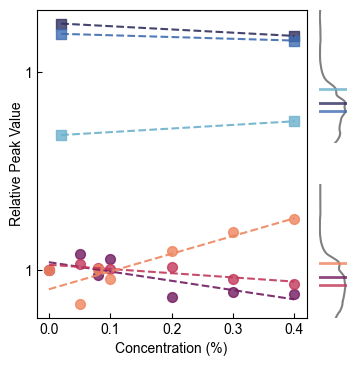

In [11]:
from scipy import stats

fig = plt.figure(figsize=(4, 4))
gs = fig.add_gridspec(2, 2, width_ratios=[3, 0.3], height_ratios=[1, 1], 
                      hspace=0.3, wspace=0.01)

# Main scatter plot (left side)
ax_main = fig.add_subplot(gs[:, 0])

# Get the last three columns (relative measurements)
relative_cols = peak_analysis_df.columns[-3:]  # ['alpha_rel_to_0.00BAC', 'beta_rel_to_0.00BAC', 'A630_rel_to_0.00BAC']

# Separate alcohol and acetaldehyde data
alcohol_mask = peak_analysis_df['series'] == 'alcohol'
acetaldehyde_mask = peak_analysis_df['series'] == 'acetaldehyde'

# Use only the second half of the colormaps (darker, more saturated colors)
alcohol_colors = Colormap('cmocean:matter')(np.linspace(0.2, 0.7, 3))
acetaldehyde_colors = Colormap('cmocean:ice')(np.linspace(0.2, 0.7, 3))

# Y-offset for acetaldehyde data to differentiate from alcohol
acetaldehyde_y_offset = 0.5

# Plot all data on the main axis
for i, col in enumerate(relative_cols):
    # Plot alcohol data
    alcohol_data = peak_analysis_df[alcohol_mask]
    if len(alcohol_data) > 0:
        ax_main.scatter(alcohol_data['concentration_%'], alcohol_data[col], 
                       color=alcohol_colors[i], 
                       label=f'Alcohol - {col.replace("_", " ").replace("rel to 0.00BAC", "").strip()}',
                       alpha=0.8, s=50, marker='o')
        
        # Add trend line for alcohol data
        if len(alcohol_data) > 1:
            x_alc = alcohol_data['concentration_%'].values
            y_alc = alcohol_data[col].values
            slope, intercept, r_value, p_value, std_err = stats.linregress(x_alc, y_alc)
            
            # Create smooth trend line
            x_trend = np.linspace(x_alc.min(), x_alc.max(), 100)
            y_trend = slope * x_trend + intercept
            
            ax_main.plot(x_trend, y_trend, color=alcohol_colors[i], 
                        linestyle='--', alpha=0.9, linewidth=1.5)
    
    # Plot acetaldehyde data with y-offset
    acetaldehyde_data = peak_analysis_df[acetaldehyde_mask]
    if len(acetaldehyde_data) > 0:
        ax_main.scatter(acetaldehyde_data['concentration_%'], 
                       acetaldehyde_data[col] + acetaldehyde_y_offset, 
                       color=acetaldehyde_colors[i], 
                       label=f'Acetaldehyde - {col.replace("_", " ").replace("rel to 0.00BAC", "").strip()}',
                       alpha=0.8, s=50, marker='s')
        
        # Add trend line for acetaldehyde data
        if len(acetaldehyde_data) > 1:
            x_acet = acetaldehyde_data['concentration_%'].values
            y_acet = acetaldehyde_data[col].values
            slope, intercept, r_value, p_value, std_err = stats.linregress(x_acet, y_acet)
            
            # Create smooth trend line
            x_trend = np.linspace(x_acet.min(), x_acet.max(), 100)
            y_trend = slope * x_trend + intercept + acetaldehyde_y_offset
            
            ax_main.plot(x_trend, y_trend, color=acetaldehyde_colors[i], 
                        linestyle='--', alpha=0.9, linewidth=1.5)

# Set up clean y-axis with only 1.00 ticks for both scales
alcohol_tick = 1.0
acetaldehyde_tick = 1.0 + acetaldehyde_y_offset
ax_main.set_yticks([alcohol_tick, acetaldehyde_tick])
ax_main.set_yticklabels(['1', '1'])

ax_main.set_xlabel('Concentration (%)')
ax_main.set_ylabel('Relative Peak Value', labelpad=0)
ax_main.tick_params(direction='in')
# ax_main.legend()

# Define peak positions and their corresponding colors
peak_positions = [575, 540, 630]  # Alpha, Beta, A630
alcohol_peak_colors = [alcohol_colors[0], alcohol_colors[1], alcohol_colors[2]]  # For alcohol spectrum
acetaldehyde_peak_colors = [acetaldehyde_colors[0], acetaldehyde_colors[1], acetaldehyde_colors[2]]  # For acetaldehyde spectrum

# Right side marginal plots - Acetaldehyde spectrum (top)
ax_acetaldehyde = fig.add_subplot(gs[0, 1])
ax_acetaldehyde.plot(acetaldehyde_spectra['0.40%_acetaldehyde_avg'], acetaldehyde_spectra['wavelength'], 
                     color='gray', linewidth=1.5)

# Add peak position markers for acetaldehyde spectrum (using blue colors)
for peak_pos, peak_color in zip(peak_positions, acetaldehyde_peak_colors):
    ax_acetaldehyde.axhline(y=peak_pos, color=peak_color, linestyle='-', linewidth=2, alpha=0.8)

ax_acetaldehyde.set_xticks([])
ax_acetaldehyde.set_yticks([])
ax_acetaldehyde.set_ylim(410, 950)
ax_acetaldehyde.tick_params(length=0)
# Remove spines
ax_acetaldehyde.spines['top'].set_visible(False)
ax_acetaldehyde.spines['right'].set_visible(False)
ax_acetaldehyde.spines['left'].set_visible(False)
ax_acetaldehyde.spines['bottom'].set_visible(False)

# Right side marginal plots - Alcohol spectrum (bottom)
ax_alcohol = fig.add_subplot(gs[1, 1])
ax_alcohol.plot(alcohol_spectra['0.08%_alcohol'], alcohol_spectra['wavelength'], 
                color='gray', linewidth=1.5)

# Add peak position markers for alcohol spectrum (using alcohol colors)
for peak_pos, peak_color in zip(peak_positions, alcohol_peak_colors):
    ax_alcohol.axhline(y=peak_pos, color=peak_color, linestyle='-', linewidth=2, alpha=0.8)

ax_alcohol.set_xticks([])
ax_alcohol.set_yticks([])
ax_alcohol.set_ylim(410, 950)
ax_alcohol.tick_params(length=0)
# Remove spines
ax_alcohol.spines['top'].set_visible(False)
ax_alcohol.spines['right'].set_visible(False)
ax_alcohol.spines['left'].set_visible(False)
ax_alcohol.spines['bottom'].set_visible(False)

pos_ax_main = deepcopy(pos_ax)
pos_ax_main.x1 -= 0.1
ax_main.set_position(pos_ax_main)
# plt.savefig('../figures/fig2/blood_alcohol_acetaldehyde_peak_trends_with_spectra.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

# For Fig1

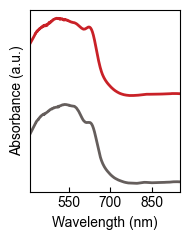

In [12]:
files = ['../data/blood_alcohol_spectra/0_00_alc_slide.csv',
         '../data/blood_alcohol_spectra/0_40_alc_slide.csv']

# Load and preprocess all data before plotting
processed_data = []
for file in files:
    data = pd.read_csv(file, skiprows=9, header=None, names=['wavelength', 'absorbance'])
    log_absorbance = np.log(data['absorbance'] + 1e-6)  # Avoid log(0)
    log_absorbance = savgol_filter(log_absorbance, window_length=121, polyorder=2)
    processed_data.append({'wavelength': data['wavelength'], 'log_absorbance': log_absorbance})

# find the wavelength array and the absorbance array of the median spectrum
S = np.vstack([d['log_absorbance'] for d in processed_data])                    # [N, L]
w = np.median(np.vstack([d['wavelength'] for d in processed_data]), axis=0)     # [L]

keep = (w >= 410) & (w <= 950)
w = w[keep]
S = S[:, keep]
r = np.median(S, axis=0)

X = np.vstack([np.ones_like(w), w, w**2, r]).T      # [L, 4]
XtX_inv = np.linalg.pinv(X.T @ X)                   # precompute for efficiency
Xt = X.T

S_emsc = np.empty_like(S)
for i, s in enumerate(S):
    a = XtX_inv @ Xt @ s
    S_emsc[i] = (s - (a[0] + a[1]*w + a[2]*w**2)) / (a[3] if a[3]!=0 else 1.0)

cm = Colormap(['#655e5c', '#c92127'])
# cm = Colormap('observable:observable10')
colors = cm(np.linspace(0, 1, len(files)))

y_offset = 2.0

plt.figure(figsize=(2, 2.5))

for i, (s, concentration) in enumerate(zip(S_emsc, alcohol_concentrations)):
    color = colors[i % len(colors)]
    plt.plot(w, s + i * y_offset, 
             color=color, linewidth=2, 
             label=f'{concentration:.2f}% alcohol')

plt.xlabel('Wavelength (nm)')
plt.ylabel('Absorbance (a.u.)')
plt.xticks(np.arange(400, 1000, 150))
plt.yticks([])

plt.xlim(410, 950)
# plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tick_params(direction='in')

plt.tight_layout()
# plt.savefig('../figures/fig1/example_blood_alcohol_spectra.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()